# Estudio 3 — Empujar dt y velocidad

**Pregunta:** ¿qué patrón hay cuando cambiamos dt (el tiempo de reacción) y la velocidad? ¿Qué se mantiene igual?

**El atajo:** si el giro y el ruido se definen *por decisión*, el modelo solo depende del **largo de paso ℓ = velocidad × dt**, es decir, de cuánto avanza un pez entre dos decisiones. Ninguna regla usa los segundos.

- **Parte A:** comprobar el atajo con el modelo real (mismo ℓ, giro por decisión o por segundo, y escalado de todas las distancias).
- **Parte B:** barrer ℓ de 0.025 a 1 BL en A0 (nuestro modelo) y A4 (Puckett).
- **Parte C:** ubicar los trials y el rango de la luz en esa curva.

## Preparación

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the parameter_studies folder (the one with study_tools.py) and let Python import from it.
TOOLS_FOLDER = Path.cwd()
while not (TOOLS_FOLDER / "study_tools.py").is_file():
    if TOOLS_FOLDER == TOOLS_FOLDER.parent:
        raise FileNotFoundError("study_tools.py was not found in this folder or any parent folder.")
    TOOLS_FOLDER = TOOLS_FOLDER.parent
if str(TOOLS_FOLDER) not in sys.path:
    sys.path.insert(0, str(TOOLS_FOLDER))

import study_tools
from study_tools import (
    A0_SETTINGS, PUCKETT_SETTINGS, A0_COLOR, PUCKETT_COLOR,
    build_model, change_settings, final_label_counts, number_of_decisions,
    record_trajectory, run_many, short_table, summarize,
)
from shiner_model import GoldenShinersModel

# Where this study keeps its results and figures.
STUDY_FOLDER = TOOLS_FOLDER / "03_dt_y_velocidad"
DATA_FOLDER = STUDY_FOLDER / "data"
FIGURE_FOLDER = STUDY_FOLDER / "figures"
DATA_FOLDER.mkdir(exist_ok=True)
FIGURE_FOLDER.mkdir(exist_ok=True)

SEEDS = list(range(10))
DT = 0.125            # our decision interval (8 decisions per second)
REPULSION_RADIUS = 0.5
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)

Dos funciones para las comparaciones exactas: una corre el modelo compartido `shiner_model.py` y guarda las posiciones después de cada decisión, y la otra mide la mayor diferencia entre dos corridas.

In [2]:
def shared_model_trajectory(speed, dt, seed, n_decisions, max_turn_rate=None, angular_noise=0.0):
    """Positions after every decision in the real shared model (shiner_model.py)."""
    model = GoldenShinersModel(speed=speed, dt=dt, seed=seed, max_turn_rate=max_turn_rate,
                               angular_noise=angular_noise, record_every=n_decisions + 1)
    return record_trajectory(model, n_decisions)


def study_model_trajectory(settings, speed, dt, seed, n_decisions):
    """Positions after every decision in the study model, with a given speed and dt."""
    changed = change_settings(settings, settings["label"], {"speed": speed, "dt": dt})
    return record_trajectory(build_model(changed, seed), n_decisions)


def largest_difference(trajectory_a, trajectory_b):
    """Largest distance (BL) between the same fish at the same decision in two runs."""
    differences = trajectory_a - trajectory_b            # shape: (decisions, fish, 2)
    distances = np.linalg.norm(differences, axis=2)      # shape: (decisions, fish)
    return distances.max()

## Parte A1 — Mismo ℓ, mismas trayectorias

Tres combinaciones con ℓ = 0.25 BL y tres con ℓ = 0.375 BL. Cada corrida dura 180 BL de nado (720 o 480 decisiones). Comparamos las posiciones **decisión por decisión**, con el modelo compartido (A0) y con el modelo de Puckett (A4, giro y ruido por decisión).

In [3]:
SAME_STEP_LENGTH = {
    0.25: [(1.0, 0.25), (2.0, 0.125), (0.5, 0.5)],
    0.375: [(3.0, 0.125), (1.5, 0.25), (6.0, 0.0625)],
}

rows = []
for step_length in SAME_STEP_LENGTH:
    pairs = SAME_STEP_LENGTH[step_length]
    n_decisions = round(180 / step_length)
    first_speed, first_dt = pairs[0]
    for seed in SEEDS:
        # A0 with the real shared model, A4 with the study model.
        reference_a0 = shared_model_trajectory(first_speed, first_dt, seed, n_decisions)
        reference_a4 = study_model_trajectory(PUCKETT_SETTINGS, first_speed, first_dt, seed, n_decisions)
        for speed, dt in pairs[1:]:
            other_a0 = shared_model_trajectory(speed, dt, seed, n_decisions)
            other_a4 = study_model_trajectory(PUCKETT_SETTINGS, speed, dt, seed, n_decisions)
            rows.append({
                "ℓ (BL)": step_length,
                "comparison": f"(v={first_speed:g}, dt={first_dt:g}) vs (v={speed:g}, dt={dt:g})",
                "seed": seed,
                "A0 largest difference (BL)": largest_difference(reference_a0, other_a0),
                "A4 largest difference (BL)": largest_difference(reference_a4, other_a4),
            })

same_step = pd.DataFrame(rows)
same_step.groupby(["ℓ (BL)", "comparison"], sort=False)[
    ["A0 largest difference (BL)", "A4 largest difference (BL)"]].max()

A0 largest difference (BL)  A4 largest difference (BL)
ℓ (BL) comparison                                                                                 
0.250  (v=1, dt=0.25) vs (v=2, dt=0.125)                           0.0                         0.0
       (v=1, dt=0.25) vs (v=0.5, dt=0.5)                           0.0                         0.0
0.375  (v=3, dt=0.125) vs (v=1.5, dt=0.25)                         0.0                         0.0
       (v=3, dt=0.125) vs (v=6, dt=0.0625)                         0.0                         0.0

In [4]:
# The shortcut must hold exactly: zero difference for every seed and every pair.
assert same_step["A0 largest difference (BL)"].max() == 0.0
assert same_step["A4 largest difference (BL)"].max() == 0.0
print("Same step length -> identical trajectories, decision by decision (", len(same_step), "comparisons ).")

Same step length -> identical trajectories, decision by decision ( 40 comparisons ).


## Parte A2 — Giro y ruido: por decisión o por segundo

Comparamos (1 BL/s, dt 0.25 s) con (2 BL/s, dt 0.125 s): las dos tienen ℓ = 0.25 BL.

- **Por segundo** (como en Trial Three): `shiner_model.py` con giro máximo de 14 rad/s, o ruido de 0.01 rad escalado con √(dt/0.125). El giro máximo por decisión es 14 × dt, así que cambia con dt (3.5 rad contra 1.75 rad).
- **Por decisión** (como Puckett): `study_model.py` con 1.75 rad y 0.01 rad por decisión, iguales para cualquier dt.

In [5]:
n_decisions = round(180 / 0.25)
turn_per_decision = change_settings(A0_SETTINGS, "giro por decisión", {"turn_per_decision": 1.75})
noise_per_decision = change_settings(A0_SETTINGS, "ruido por decisión", {"noise_per_decision": 0.01})

rows = []
for seed in SEEDS:
    rows.append({"version": "giro 14 rad/s (por segundo, shiner_model)", "seed": seed,
                 "largest difference (BL)": largest_difference(
                     shared_model_trajectory(1.0, 0.25, seed, n_decisions, max_turn_rate=14.0),
                     shared_model_trajectory(2.0, 0.125, seed, n_decisions, max_turn_rate=14.0))})
    rows.append({"version": "giro 1.75 rad por decisión (study_model)", "seed": seed,
                 "largest difference (BL)": largest_difference(
                     study_model_trajectory(turn_per_decision, 1.0, 0.25, seed, n_decisions),
                     study_model_trajectory(turn_per_decision, 2.0, 0.125, seed, n_decisions))})
    rows.append({"version": "ruido 0.01 rad escalado con √dt (por segundo, shiner_model)", "seed": seed,
                 "largest difference (BL)": largest_difference(
                     shared_model_trajectory(1.0, 0.25, seed, n_decisions, angular_noise=0.01),
                     shared_model_trajectory(2.0, 0.125, seed, n_decisions, angular_noise=0.01))})
    rows.append({"version": "ruido 0.01 rad por decisión (study_model)", "seed": seed,
                 "largest difference (BL)": largest_difference(
                     study_model_trajectory(noise_per_decision, 1.0, 0.25, seed, n_decisions),
                     study_model_trajectory(noise_per_decision, 2.0, 0.125, seed, n_decisions))})

turn_and_noise = pd.DataFrame(rows)
turn_and_noise.groupby("version", sort=False)["largest difference (BL)"].agg(["min", "median", "max"])

,min,median,max
version,,,
"giro 14 rad/s (por segundo, shiner_model)",16.371,20.657,24.608
giro 1.75 rad por decisión (study_model),0.000,0.000,0.000
"ruido 0.01 rad escalado con √dt (por segundo, shiner_model)",11.684,21.300,24.680
ruido 0.01 rad por decisión (study_model),0.000,0.000,0.000


In [6]:
# Per decision: the shortcut holds exactly. Per second: it does not.
per_decision = turn_and_noise[turn_and_noise["version"].str.contains("por decisión")]
per_second = turn_and_noise[turn_and_noise["version"].str.contains("por segundo")]
assert per_decision["largest difference (BL)"].max() == 0.0
assert per_second["largest difference (BL)"].min() > 0.0
print("Per decision: identical. Per second: different in every seed.")

Per decision: identical. Per second: different in every seed.


## Parte A3 — Escalado: multiplicar todas las distancias por 2

Multiplicamos por 2 los tres radios, el tamaño de la arena y ℓ (la velocidad). Si solo importan las proporciones, el modelo grande es el chico "con zoom": sus posiciones divididas por 2 tienen que ser iguales a las del chico.

In [7]:
def scaled(settings, factor):
    """The same configuration with every distance (radii, arena, step length) multiplied by factor."""
    changes = {
        "repulsion_radius": settings["repulsion_radius"] * factor,
        "orientation_radius": settings["orientation_radius"] * factor,
        "attraction_radius": settings["attraction_radius"] * factor,
        "arena": settings["arena"] * factor,
        "speed": settings["speed"] * factor,
    }
    return change_settings(settings, settings["label"] + f" x{factor:g}", changes)


rows = []
for settings in [A0_SETTINGS, PUCKETT_SETTINGS]:
    big = scaled(settings, 2)
    for seed in SEEDS:
        small_run = record_trajectory(build_model(settings, seed), 1440)
        big_run = record_trajectory(build_model(big, seed), 1440)
        rows.append({"configuration": settings["label"], "seed": seed,
                     "largest difference (BL)": largest_difference(big_run / 2, small_run)})

scaling = pd.DataFrame(rows)
scaling.groupby("configuration")["largest difference (BL)"].max()

configuration
A0    0.0
A4    0.0
Name: largest difference (BL), dtype: float64

In [8]:
assert scaling["largest difference (BL)"].max() == 0.0
print("Doubling every distance gives exactly the same school, twice as big.")

Doubling every distance gives exactly the same school, twice as big.


## Parte B — Barrer el largo de paso ℓ

ℓ = 0.025 … 1.0 BL por decisión. Con dt = 0.125 s, eso es una velocidad de 0.2 a 8 BL/s. En todas las corridas los peces nadan 180 BL, así que hay 180 / ℓ decisiones. Lo hacemos para A0 y para A4 (10 seeds cada uno: 220 simulaciones).

In [9]:
STEP_LENGTHS = [0.025, 0.05, 0.1, 0.125, 0.2, 0.25, 0.375, 0.5, 0.625, 0.75, 1.0]

step_length_runs = []
for base in [A0_SETTINGS, PUCKETT_SETTINGS]:
    for step_length in STEP_LENGTHS:
        speed = step_length / DT
        label = f"{base['base']}, ℓ={step_length:g}"
        step_length_runs.append(change_settings(base, label, {"speed": speed}))

for settings in step_length_runs[:3]:
    print(settings["label"], "speed", settings["speed"], "decisions", number_of_decisions(settings["speed"], DT))

A0, ℓ=0.025 speed 0.2 decisions 7200
A0, ℓ=0.05 speed 0.4 decisions 3600
A0, ℓ=0.1 speed 0.8 decisions 1800


In [10]:
step_results = run_many(step_length_runs, SEEDS, DATA_FOLDER / "part_b_step_length.csv")
step_summary = summarize(step_results, ["label", "base", "step_length"])

Loaded saved results from part_b_step_length.csv (set study_tools.RERUN = True to simulate again).


### Resultados de la parte B

In [11]:
short_table(step_summary)

,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,"A0, ℓ=0.025",9/10,0.94 ± 0.05,0.08 ± 0.07,0.52 ± 0.00,0.90 ± 0.10,0.00 ± 0.00,0.45 ± 0.00
1,"A0, ℓ=0.05",10/10,0.99 ± 0.00,0.02 ± 0.00,0.54 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.41 ± 0.00
2,"A0, ℓ=0.1",10/10,0.97 ± 0.00,0.02 ± 0.00,0.56 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.33 ± 0.01
3,"A0, ℓ=0.125",10/10,0.95 ± 0.00,0.03 ± 0.00,0.57 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.00
4,"A0, ℓ=0.2",6/10,0.90 ± 0.01,0.04 ± 0.00,0.60 ± 0.00,1.00 ± 0.00,0.05 ± 0.01,0.15 ± 0.01
5,"A0, ℓ=0.25",0/10,0.85 ± 0.01,0.09 ± 0.03,0.61 ± 0.00,0.94 ± 0.06,0.12 ± 0.01,0.07 ± 0.01
6,"A0, ℓ=0.375",0/10,0.69 ± 0.01,0.07 ± 0.00,0.59 ± 0.00,1.00 ± 0.00,0.51 ± 0.02,0.02 ± 0.00
7,"A0, ℓ=0.5",0/10,0.53 ± 0.01,0.08 ± 0.00,0.56 ± 0.00,1.00 ± 0.00,0.70 ± 0.02,0.02 ± 0.00
8,"A0, ℓ=0.625",0/10,0.48 ± 0.01,0.08 ± 0.00,0.56 ± 0.00,1.00 ± 0.00,0.74 ± 0.01,0.03 ± 0.00
9,"A0, ℓ=0.75",0/10,0.46 ± 0.01,0.09 ± 0.00,0.57 ± 0.00,1.00 ± 0.00,0.76 ± 0.02,0.02 ± 0.00


In [12]:
final_label_counts(step_results)

label_final,polarized,milling,swarm,fragmented
label,,,,
"A0, ℓ=0.025",9,0,0,1
"A0, ℓ=0.05",10,0,0,0
"A0, ℓ=0.1",10,0,0,0
"A0, ℓ=0.125",10,0,0,0
"A0, ℓ=0.2",10,0,0,0
"A0, ℓ=0.25",9,0,0,1
"A0, ℓ=0.375",7,0,3,0
"A0, ℓ=0.5",0,0,10,0
"A0, ℓ=0.625",0,0,10,0


### Figura B — Todo en función de ℓ

Línea vertical: el radio de repulsión (0.5 BL). Franja sombreada: el rango de ℓ que va a tener la luz (0.025–0.625 BL, es decir, 0.2–5 BL/s). El eje x es logarítmico.

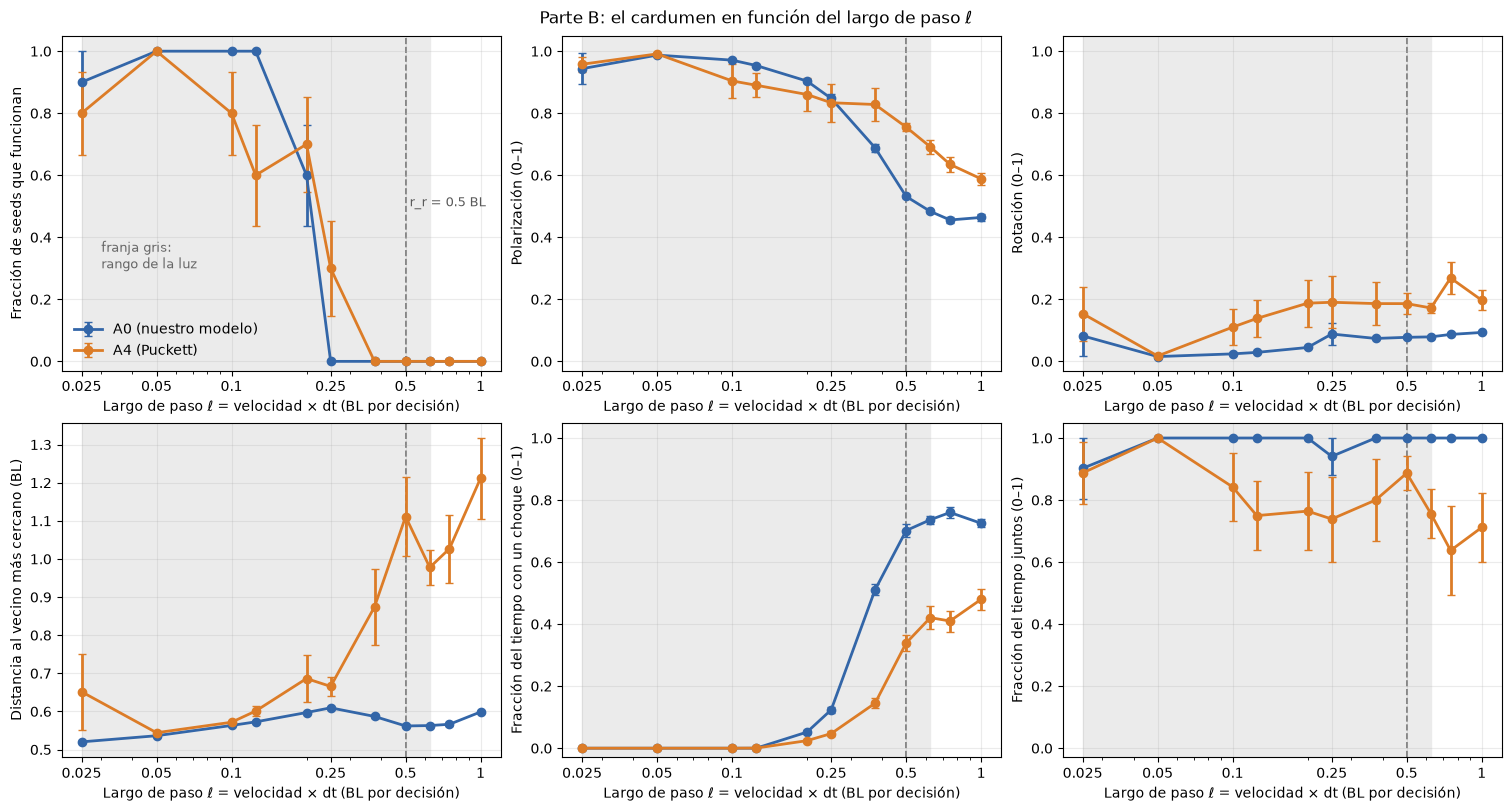

In [13]:
FIGURE_B_TITLE = "Parte B: el cardumen en función del largo de paso ℓ"

panels = [
    ("works", "Fracción de seeds que funcionan"),
    ("polarization", "Polarización (0–1)"),
    ("rotation", "Rotación (0–1)"),
    ("nnd", "Distancia al vecino más cercano (BL)"),
    ("collision_fraction", "Fracción del tiempo con un choque (0–1)"),
    ("together_fraction", "Fracción del tiempo juntos (0–1)"),
]
BASE_COLORS = {"A0": A0_COLOR, "A4": PUCKETT_COLOR}
BASE_NAMES = {"A0": "A0 (nuestro modelo)", "A4": "A4 (Puckett)"}

fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
for axis, (column, axis_label) in zip(axes.flat, panels):
    axis.axvspan(0.025, 0.625, color="0.92", zorder=0)
    axis.axvline(REPULSION_RADIUS, color="0.45", linestyle="--", linewidth=1.2, zorder=1)
    for base in ["A0", "A4"]:
        rows = step_summary[step_summary["base"] == base]
        axis.errorbar(rows["step_length"], rows[column], yerr=rows[column + "_se"], color=BASE_COLORS[base],
                      marker="o", markersize=6, linewidth=2, capsize=3, label=BASE_NAMES[base], zorder=2)
    axis.set_xscale("log")
    axis.set_xticks([0.025, 0.05, 0.1, 0.25, 0.5, 1.0])
    axis.set_xticklabels(["0.025", "0.05", "0.1", "0.25", "0.5", "1"])
    axis.set_xlabel("Largo de paso ℓ = velocidad × dt (BL por decisión)")
    axis.set_ylabel(axis_label)
    axis.grid(alpha=0.25)
    if column != "nnd":
        axis.set_ylim(-0.03, 1.05)
axes[0, 0].legend(frameon=False, loc="lower left")
axes[0, 0].text(0.5, 0.5, " r_r = 0.5 BL", color="0.35", fontsize=9)
axes[0, 0].text(0.03, 0.3, "franja gris:\nrango de la luz", color="0.4", fontsize=9)
fig.suptitle(FIGURE_B_TITLE)
fig.savefig(FIGURE_FOLDER / "part_b_step_length.png", dpi=150)
plt.show()

### Figura B2 — ¿Por qué aparecen los choques? La regla 0.5 − 2ℓ

Dos peces que nadan uno hacia el otro se acercan hasta 2ℓ en una sola decisión. Si empiezan justo afuera de la zona de repulsión (0.5 BL), pueden quedar a 0.5 − 2ℓ antes de poder reaccionar. La línea gris es esa regla; los puntos son la distancia más chica medida en cada corrida (media de 10 seeds). La línea punteada es el umbral de choque (0.25 BL): la regla lo cruza en **ℓ = 0.125 BL**, justo donde los choques empiezan.

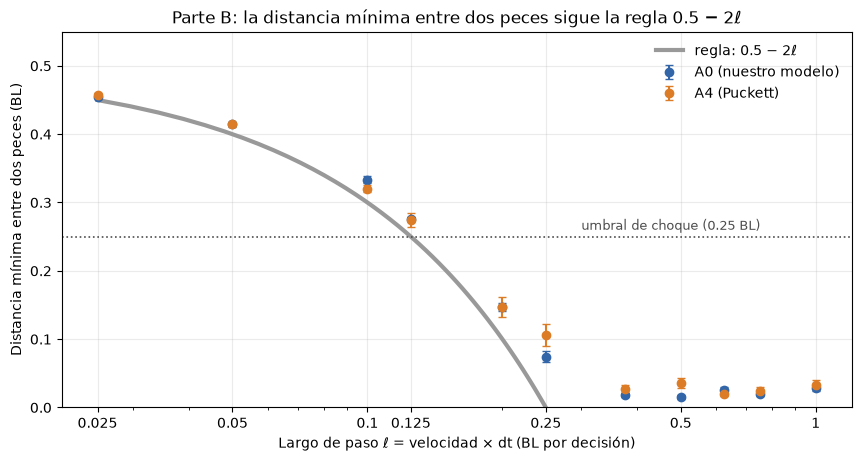

In [14]:
FIGURE_B2_TITLE = "Parte B: la distancia mínima entre dos peces sigue la regla 0.5 − 2ℓ"

rule_steps = np.linspace(0.025, 0.25, 50)
fig, axis = plt.subplots(figsize=(8.5, 4.5), constrained_layout=True)
axis.plot(rule_steps, REPULSION_RADIUS - 2 * rule_steps, color="0.6", linewidth=3, label="regla: 0.5 − 2ℓ")
for base in ["A0", "A4"]:
    rows = step_summary[step_summary["base"] == base]
    axis.errorbar(rows["step_length"], rows["min_pair_distance"], yerr=rows["min_pair_distance_se"],
                  color=BASE_COLORS[base], marker="o", markersize=6, linestyle="none", capsize=3,
                  label=BASE_NAMES[base])
axis.axhline(study_tools.COLLISION_DISTANCE, color="0.3", linestyle=":", linewidth=1.2)
axis.text(0.3, study_tools.COLLISION_DISTANCE + 0.01, "umbral de choque (0.25 BL)", color="0.3", fontsize=9)
axis.set_xscale("log")
axis.set_xticks([0.025, 0.05, 0.1, 0.125, 0.25, 0.5, 1.0])
axis.set_xticklabels(["0.025", "0.05", "0.1", "0.125", "0.25", "0.5", "1"])
axis.set_xlabel("Largo de paso ℓ = velocidad × dt (BL por decisión)")
axis.set_ylabel("Distancia mínima entre dos peces (BL)")
axis.set_ylim(0, 0.55)
axis.grid(alpha=0.25)
axis.legend(frameon=False, loc="upper right")
axis.set_title(FIGURE_B2_TITLE)
fig.savefig(FIGURE_FOLDER / "part_b_minimum_distance.png", dpi=150)
plt.show()

## Parte C — Los trials y la luz sobre la curva de ℓ

Los trials cambiaban dt con la velocidad fija, así que en realidad cambiaban ℓ:

| Trial | Velocidades (BL/s) | dt (s) | ℓ (BL por decisión) |
|---|---|---|---|
| Trial One (notebook 04) | 1 y 5 | 0.125, 0.0625, 0.03125 | 0.031–0.625 |
| Trial Two (notebook 02) | 1, 3 y 5 | 0.0625, 0.03125, 0.015625 | 0.016–0.31 |
| Trial Three | 1, 3 y 5 | 0.0078–0.031 | 0.008–0.156 |
| Luz (plan) | 0.2–5 | 0.125 | 0.025–0.625 |

Para ver la curva también en los ℓ más chicos de Trial Three, agregamos dos valores extra, **0.00625 y 0.0125 BL** (no están en el README; son 28 800 y 14 400 decisiones por corrida).

In [15]:
EXTRA_STEP_LENGTHS = [0.00625, 0.0125]

extra_runs = []
for base in [A0_SETTINGS, PUCKETT_SETTINGS]:
    for step_length in EXTRA_STEP_LENGTHS:
        label = f"{base['base']}, ℓ={step_length:g}"
        extra_runs.append(change_settings(base, label, {"speed": step_length / DT}))

extra_results = run_many(extra_runs, SEEDS, DATA_FOLDER / "part_c_small_step_lengths.csv")
extra_summary = summarize(extra_results, ["label", "base", "step_length"])
short_table(extra_summary)

Loaded saved results from part_c_small_step_lengths.csv (set study_tools.RERUN = True to simulate again).


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,"A0, ℓ=0.00625",9/10,0.96 ± 0.04,0.10 ± 0.07,0.52 ± 0.01,0.90 ± 0.10,0.00 ± 0.00,0.49 ± 0.00
1,"A0, ℓ=0.0125",10/10,1.00 ± 0.00,0.03 ± 0.00,0.51 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.48 ± 0.00
2,"A4, ℓ=0.00625",9/10,0.99 ± 0.01,0.06 ± 0.01,0.55 ± 0.03,0.99 ± 0.01,0.00 ± 0.00,0.49 ± 0.00
3,"A4, ℓ=0.0125",5/10,0.89 ± 0.06,0.18 ± 0.08,0.55 ± 0.01,0.78 ± 0.10,0.00 ± 0.00,0.48 ± 0.00


Trial One (notebook 04, 5 BL/s, 31.25 s, 20 × 20 BL, 360°, giro de golpe) midió la polarización final con tres dt. Esas tres corridas son nuestro A0 con ℓ = 0.625, 0.3125 y 0.156 BL. Las ponemos sobre la curva de A0 (valores copiados de `handlings/trial_one/README.md`).

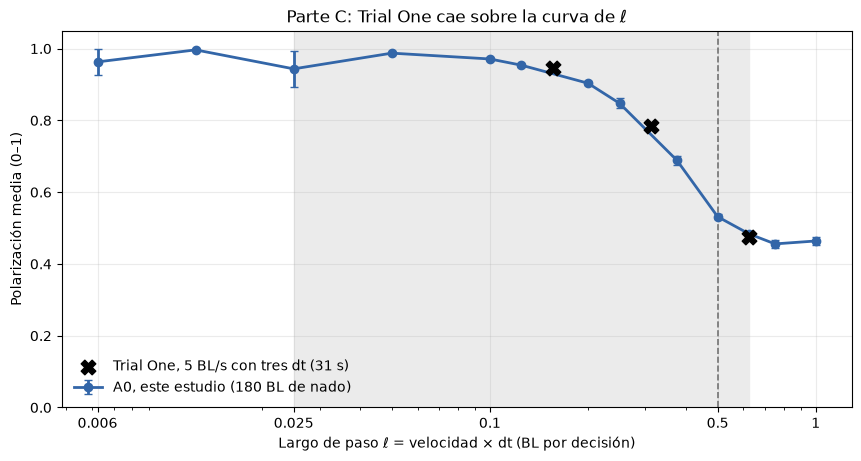

In [16]:
FIGURE_C_TITLE = "Parte C: Trial One cae sobre la curva de ℓ"

# Trial One, timestep table at 5 BL/s: (step length, mean late polarization).
TRIAL_ONE = [(0.625, 0.4760), (0.3125, 0.7854), (0.15625, 0.9447)]

all_a0 = pd.concat([extra_summary[extra_summary["base"] == "A0"],
                    step_summary[step_summary["base"] == "A0"]]).sort_values("step_length")

fig, axis = plt.subplots(figsize=(8.5, 4.5), constrained_layout=True)
axis.axvspan(0.025, 0.625, color="0.92", zorder=0)
axis.axvline(REPULSION_RADIUS, color="0.45", linestyle="--", linewidth=1.2)
axis.errorbar(all_a0["step_length"], all_a0["polarization"], yerr=all_a0["polarization_se"], color=A0_COLOR,
              marker="o", markersize=6, linewidth=2, capsize=3, label="A0, este estudio (180 BL de nado)")
trial_steps = []
trial_values = []
for step_length, polarization in TRIAL_ONE:
    trial_steps.append(step_length)
    trial_values.append(polarization)
axis.scatter(trial_steps, trial_values, marker="X", s=110, color="black", zorder=3,
             label="Trial One, 5 BL/s con tres dt (31 s)")
axis.set_xscale("log")
axis.set_xticks([0.00625, 0.025, 0.1, 0.5, 1.0])
axis.set_xticklabels(["0.006", "0.025", "0.1", "0.5", "1"])
axis.set_xlabel("Largo de paso ℓ = velocidad × dt (BL por decisión)")
axis.set_ylabel("Polarización media (0–1)")
axis.set_ylim(0, 1.05)
axis.grid(alpha=0.25)
axis.legend(frameon=False, loc="lower left")
axis.set_title(FIGURE_C_TITLE)
fig.savefig(FIGURE_FOLDER / "part_c_trials_on_curve.png", dpi=150)
plt.show()

## Guardar todos los resultados juntos

In [17]:
step_results["part"] = "B"
extra_results["part"] = "C (extra)"
all_results = pd.concat([step_results, extra_results], ignore_index=True)
all_results.to_csv(DATA_FOLDER / "results.csv", index=False)
print(len(all_results), "simulations saved in data/results.csv")

260 simulations saved in data/results.csv


## Conclusión

Ver las secciones "Resultados" y "Conclusión" del [README](README.md) de este estudio.